In [2]:
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, log_loss, f1_score

RANDOM_STATE = 42

In [6]:
ml_data = pd.read_csv("Dataset/features.csv", parse_dates=["match_date"])

feature_cols = ["home_recent_5", "away_recent_5", "form_diff",
                "home_win_rate", "away_win_rate",
                "home_avg_gf", "home_avg_ga", "away_avg_gf", "away_avg_ga",
                "home_position", "away_position", "position_diff"]


In [7]:
def evaluate(model, X, y):
    proba = model.predict_proba(X)
    pred = model.predict(X)
    return (accuracy_score(y, pred),
            log_loss(y, proba, labels=[0, 1, 2]),
            f1_score(y, pred, average="macro"))

logreg = Pipeline([("scaler", StandardScaler()),
                   ("lr", LogisticRegression(max_iter=1000))])

rf = RandomForestClassifier(n_estimators=300, max_depth=6,
                            min_samples_leaf=10, random_state=RANDOM_STATE)

xgb_tuned = XGBClassifier(n_estimators=300, max_depth=2, learning_rate=0.03,
                          subsample=0.8, colsample_bytree=0.8,
                          eval_metric="mlogloss", random_state=RANDOM_STATE)

In [8]:
matches = pd.read_csv("Dataset/matches_clean.csv", parse_dates=["match_date"])
matches = matches.sort_values(["match_date", "id"]).reset_index(drop=True)
print(matches.shape)

(7967, 25)


In [9]:
def compute_elo(df, k=20, hfa=60, carry=0.75, start=1500):
    ratings = {}
    rows = []
    prev_season = None

    for r in df.itertuples():
        # New season: pull every rating part of the way back toward 1500
        if r.season_start_year != prev_season:
            for t in ratings:
                ratings[t] = start + carry * (ratings[t] - start)
            prev_season = r.season_start_year

        h = ratings.get(r.home, start)   # pre-match ratings
        a = ratings.get(r.away, start)
        rows.append((r.id, h, a))        # store BEFORE updating (no leakage)

        expected_h = 1 / (1 + 10 ** ((a - (h + hfa)) / 400))
        if r.home_score > r.away_score:
            actual = 1.0
        elif r.home_score == r.away_score:
            actual = 0.5
        else:
            actual = 0.0

        change = k * (actual - expected_h)
        ratings[r.home] = h + change
        ratings[r.away] = a - change

    elo_df = pd.DataFrame(rows, columns=["id", "home_elo", "away_elo"])
    return elo_df, ratings

In [10]:
base = ml_data[["id", "season_start_year", "target_encoded"]]
results = []

for k in [10, 20, 30, 40]:
    for hfa in [0, 50, 100]:
        for carry in [0.6, 0.75, 1.0]:
            elo_df, _ = compute_elo(matches, k=k, hfa=hfa, carry=carry)
            tmp = base.merge(elo_df, on="id")
            tmp["elo_diff"] = tmp["home_elo"] - tmp["away_elo"]

            tr = tmp[tmp["season_start_year"] <= 2015]
            va = tmp[tmp["season_start_year"].between(2016, 2018)]

            lr = LogisticRegression(max_iter=1000)
            lr.fit(tr[["elo_diff"]], tr["target_encoded"])
            ll = log_loss(va["target_encoded"], lr.predict_proba(va[["elo_diff"]]))
            results.append((k, hfa, carry, ll))

res = pd.DataFrame(results, columns=["K", "HFA", "carry", "val_logloss"]).sort_values("val_logloss")
print(res.head(8))

     K  HFA  carry  val_logloss
8   10  100   1.00     0.930761
5   10   50   1.00     0.930978
2   10    0   1.00     0.931088
17  20  100   1.00     0.934139
7   10  100   0.75     0.934346
14  20   50   1.00     0.934518
4   10   50   0.75     0.934555
1   10    0   0.75     0.934680


In [ ]:
best = res.iloc[0]
elo_df, final_ratings = compute_elo(matches, k=int(best.K), hfa=int(best.HFA), carry=best.carry)

print(elo_df.head(2))   # first matches: both teams 1500 (but should start at 1500 or else error)
print(pd.Series(final_ratings).sort_values(ascending=False).head(5))
print(pd.Series(final_ratings).sort_values().head(5))

      id  home_elo  away_elo
0  18123    1500.0    1500.0
1  18124    1500.0    1500.0
Manchester City      1810.469857
Liverpool            1788.134514
Chelsea              1685.227131
Manchester United    1660.205352
Tottenham Hotspur    1653.550608
dtype: float64
Derby County           1355.802706
Norwich City           1374.915922
Huddersfield Town      1409.213166
Queens Park Rangers    1412.412276
Fulham                 1416.518279
dtype: float64


In [ ]:
#Merger with ml_data
ml_data = ml_data.drop(columns=["home_elo", "away_elo", "elo_diff"], errors="ignore")
ml_data = ml_data.merge(elo_df, on="id", how="left")
ml_data["elo_diff"] = ml_data["home_elo"] - ml_data["away_elo"]

feature_cols_elo = feature_cols + ["home_elo", "away_elo", "elo_diff"]
print(ml_data[feature_cols_elo].isna().sum().sum())   # must be 0

0


In [13]:
#Before vs After validation

train_m = ml_data["season_start_year"] <= 2015
val_m   = ml_data["season_start_year"].between(2016, 2018)
test_m  = ml_data["season_start_year"] >= 2019
y_tr = ml_data.loc[train_m, "target_encoded"]
y_va = ml_data.loc[val_m, "target_encoded"]

compare = []
for name, model in {"LogReg": logreg, "RandomForest": rf, "XGBoost (tuned)": xgb_tuned}.items():
    for tag, cols in [("without Elo", feature_cols), ("with Elo", feature_cols_elo)]:
        m = clone(model).fit(ml_data.loc[train_m, cols], y_tr)
        acc, ll, f1 = evaluate(m, ml_data.loc[val_m, cols], y_va)
        compare.append((name, tag, acc, ll, f1))

pd.DataFrame(compare, columns=["model", "features", "val_acc", "val_logloss", "val_macroF1"]).round(4)

,model,features,val_acc,val_logloss,val_macroF1
0,LogReg,without Elo,0.5678,0.9445,0.4121
1,LogReg,with Elo,0.5714,0.9333,0.4153
2,RandomForest,without Elo,0.5842,0.9384,0.4241
3,RandomForest,with Elo,0.5833,0.9340,0.4331
4,XGBoost (tuned),without Elo,0.5806,0.9344,0.4212
5,XGBoost (tuned),with Elo,0.5751,0.9308,0.4200


In [14]:
final_cols = feature_cols_elo      # or feature_cols, per the decision rule
final_model = clone(xgb_tuned).fit(ml_data.loc[train_m | val_m, final_cols],
                                   ml_data.loc[train_m | val_m, "target_encoded"])
print(evaluate(final_model, ml_data.loc[test_m, final_cols], ml_data.loc[test_m, "target_encoded"]))

(0.5128913443830571, 1.0006341934204102, 0.37511523261728685)


In [15]:
rows = []
for name, model in {"LogReg": logreg, "RandomForest": rf, "XGBoost (tuned)": xgb_tuned}.items():
    m = clone(model).fit(ml_data.loc[train_m, feature_cols_elo], y_tr)
    acc, ll, f1 = evaluate(m, ml_data.loc[val_m, feature_cols_elo], y_va)
    rows.append((name, acc, ll, f1))

final_table = pd.DataFrame(rows, columns=["model", "val_acc", "val_logloss", "val_macroF1"]).round(4)
final_table

,model,val_acc,val_logloss,val_macroF1
0,LogReg,0.5714,0.9333,0.4153
1,RandomForest,0.5833,0.9340,0.4331
2,XGBoost (tuned),0.5751,0.9308,0.4200


XGboost wins again with ELO introduced as well (with Logloss as primary evaluation metric). But generally all 3 models perform just about the same, with and without ELO.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from sklearn.metrics import confusion_matrix
from sklearn.inspection import permutation_importance

Path("outputs").mkdir(exist_ok=True)
labels = ["Away", "Draw", "Home"]

In [17]:
final_table.to_csv("outputs/model_comparison.csv", index=False)
joblib.dump(final_model, "Dataset/final_model.pkl")

['Dataset/final_model.pkl']

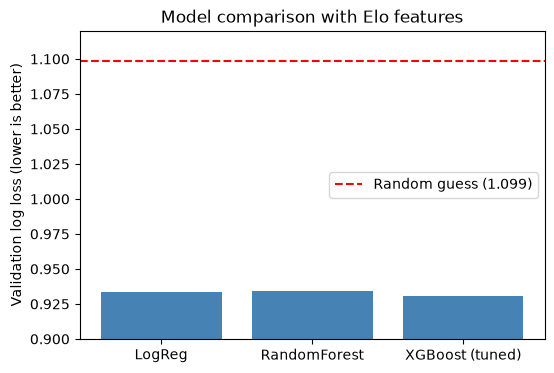

In [ ]:
#model comparison

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(final_table["model"], final_table["val_logloss"], color="steelblue")
ax.axhline(1.0986, color="red", linestyle="--", label="Random guess (1.099)")
ax.set_ylim(0.90, 1.12)
ax.set_ylabel("Validation log loss (lower is better)")
ax.set_title("Model comparison with Elo features")
ax.legend()
fig.savefig("outputs/model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

XGboost (tuned) has lowest score, so its the overall winner

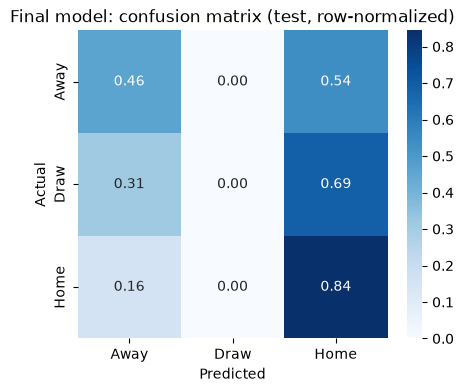

In [20]:
#normalized confusion matrix
X_test = ml_data.loc[test_m, final_cols]
y_test = ml_data.loc[test_m, "target_encoded"]

cm = confusion_matrix(y_test, final_model.predict(X_test), normalize="true")
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Final model: confusion matrix (test, row-normalized)")
fig.savefig("outputs/confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

Draw at near zero because it's the lowest probability from the predict() method. if we add weight to predict it,it'll just swap home/away predictions for wrong draw predictions.

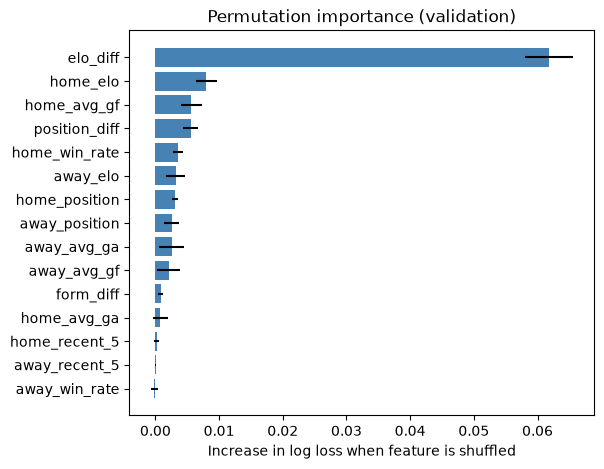

In [ ]:
#Important features for better logloss
m_tr = clone(xgb_tuned).fit(ml_data.loc[train_m, final_cols], y_tr)
pi = permutation_importance(m_tr, ml_data.loc[val_m, final_cols], y_va,
                            scoring="neg_log_loss", n_repeats=10,
                            random_state=RANDOM_STATE)

imp = pd.Series(pi.importances_mean, index=final_cols).sort_values()
fig, ax = plt.subplots(figsize=(6, 5))
ax.barh(imp.index, imp.values, xerr=pd.Series(pi.importances_std, index=final_cols)[imp.index],
        color="steelblue")
ax.set_xlabel("Increase in log loss when feature is shuffled")
ax.set_title("Permutation importance (validation)")
fig.savefig("outputs/permutation_importance.png", dpi=200, bbox_inches="tight")
plt.show()

In [22]:
#calibration by season (test)

proba = final_model.predict_proba(X_test)
cal = pd.DataFrame({
    "season": ml_data.loc[test_m, "season_start_year"].values,
    "p_away": proba[:, 0], "p_draw": proba[:, 1], "p_home": proba[:, 2],
    "act_away": (y_test.values == 0), "act_draw": (y_test.values == 1),
    "act_home": (y_test.values == 2)})
cal_table = cal.groupby("season").mean().round(3)
cal_table.to_csv("outputs/calibration_by_season.csv")
cal_table

,p_away,p_draw,p_home,act_away,act_draw,act_home
season,,,,,,
2019,0.297,0.235,0.468,0.305,0.241,0.454
2020,0.293,0.236,0.471,0.394,0.226,0.380
2021,0.299,0.232,0.468,0.339,0.239,0.422


In [38]:
result_name = {0: "Away win", 1: "Draw", 2: "Home win"}

def check_match(home, away, season=None):
    m = ml_data[(ml_data["home"] == home) & (ml_data["away"] == away)]
    if season is not None:
        m = m[m["season_start_year"] == season]
    if m.empty:
        print("No match found. Check spelling, or the season may have been dropped in warm-up.")
        return

    probs = final_model.predict_proba(m[final_cols])
    for (_, r), p in zip(m.iterrows(), probs):
        seen = "yes (training data)" if r["season_start_year"] <= 2018 else "no (test data)"
        print(f"\n{home} vs {away} | {r['match_date'].date()} | season {r['season_start_year']}")
        print(f"Elo: {r['home_elo']:.0f} vs {r['away_elo']:.0f}")
        print(f"P(home) = {p[2]:.1%}   P(draw) = {p[1]:.1%}   P(away) = {p[0]:.1%}")
        print(f"Model's pick: {result_name[p.argmax()]} | Actual: {result_name[r['target_encoded']]}")
        print(f"Model saw this match when training? {seen}")

#home, away, year
check_match("Manchester United", "Liverpool", season=2021)


Manchester United vs Liverpool | 2021-10-24 | season 2021
Elo: 1686 vs 1757
P(home) = 35.0%   P(draw) = 30.1%   P(away) = 34.8%
Model's pick: Home win | Actual: Away win
Model saw this match when training? no (test data)


### single out games and predict them